# 01 - Carga, limpieza y calidad de los datos

**Objetivo:** dejar los datos en un solo formato confiable y entender qué tan buenos son antes de modelar.

Preguntas que contesta este notebook:
1. ¿Los cuatro archivos dicen lo mismo? (¿el histórico coincide con los crudos?)
2. ¿Qué problemas de calidad hay? (formatos, huecos, valores repetidos, saltos)
3. ¿Qué materias primas reales podrían ser X, Y y Z?
4. ¿Cómo se ven las series y cómo se relacionan a simple vista?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import datos
from src.graficas import COLORES, estilo, guardar

estilo()
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Carga de los archivos crudos

Cada archivo viene en un formato distinto:

| Archivo | Separador | Decimal | Fechas | Detalle |
|---|---|---|---|---|
| X.csv | , | . | aaaa-mm-dd | orden descendente |
| Y.csv | ; | , | día/mes/año | trae BOM (caracter invisible al inicio) |
| Z.csv | , | . | aaaa-mm-dd | columnas invertidas (Price, Date) |

La función datos.cargar_insumo resuelve cada caso y devuelve una serie ordenada por fecha.

In [2]:
insumos = datos.cargar_insumos()
hist = datos.cargar_historico()

pd.DataFrame({n: {"inicio": s.index.min().date(), "fin": s.index.max().date(), "observaciones": len(s)}
              for n, s in insumos.items()}).T

,inicio,fin,observaciones
X,1988-06-27,2024-04-04,9144
Y,2006-07-11,2023-09-12,4485
Z,2010-01-01,2023-08-31,3565


In [3]:
hist.head()

,X,Y,Z,Equipo1,Equipo2
Date,,,,,
2010-01-04,80.12,527.50,"2,225.25",434.73,931.73
2010-01-05,80.59,527.50,"2,246.50",449.97,968.56
2010-01-06,81.89,527.50,"2,302.50",444.48,960.51
2010-01-07,81.51,527.50,"2,306.50",440.90,960.14
2010-01-08,81.37,552.50,"2,261.25",448.82,949.55


## 2. ¿El histórico coincide con los archivos crudos?

Se compara fecha por fecha. Si coincide al 100%, podemos usar "historico_equipos.csv" con confianza,
y los archivos crudos solo aportan historia extra (por ejemplo, X llega hasta abril de 2024).

In [4]:
datos.validar_historico(hist, insumos)

,fechas_historico,fechas_en_crudo,coinciden_%,error_max
insumo,,,,
X,3530,3530,100.00,0.00
Y,3530,3530,100.00,0.00
Z,3530,3530,100.00,0.00


**Resultado:** las 3,530 fechas del histórico coinciden al 100% con los crudos (error máximo 0).
El histórico es la **intersección** de los días en que existen las tres materias primas
(por eso le faltan algunos dias feriados que sí tiene Z, como 1-ene o Viernes Santo).

## 3. Reporte de calidad por serie

In [5]:
calidad = pd.DataFrame({n: datos.reporte_calidad(s) for n, s in insumos.items()})
calidad["Equipo1"] = pd.Series(datos.reporte_calidad(hist["Equipo1"]))
calidad["Equipo2"] = pd.Series(datos.reporte_calidad(hist["Equipo2"]))
calidad

,X,Y,Z,Equipo1,Equipo2
inicio,1988-06-27,2006-07-11,2010-01-01,2010-01-04,2010-01-04
fin,2024-04-04,2023-09-12,2023-08-31,2023-08-31,2023-08-31
observaciones,9144,4485,3565,3530,3530
nulos,0,0,0,0,0
precios_<=0,0,0,0,0,0
dias_repetidos,84,2815,180,1,3
racha_max_sin_cambio,2,70,3,2,2
saltos_>10%,36,15,3,6,2
fines_de_semana,2,4,0,0,0


"Y" tiene miles de días con el mismo precio que el día anterior.
Veamos, por año, qué porcentaje de días no cambió:

In [6]:
datos.frecuencia_real_Y(insumos["Y"]).to_frame("% días sin cambio")

,% días sin cambio
Date,
2006,92.70
2007,92.70
2008,90.50
2009,88.10
2010,84.40
2011,86.90
2012,85.10
2013,87.40
2014,91.60


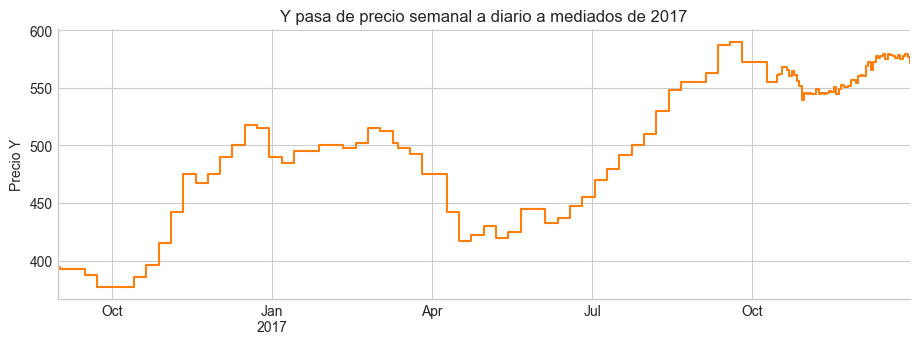

In [7]:
y = insumos["Y"]
fig, ax = plt.subplots(figsize=(11, 3.5))
y["2016-09":"2017-12"].plot(ax=ax, color=COLORES["Y"], drawstyle="steps-post")
ax.set_title("Y pasa de precio semanal a diario a mediados de 2017")
ax.set_xlabel("")
ax.set_ylabel("Precio Y")
guardar(fig, "01_Y_semanal_a_diario")


Hasta mediados de 2017, "Y" era un precio semanal, cambiaba un día y se repetía los otros 4.
En total, 2,815 días de "Y" repiten el precio del día anterior. Por consecuencias:

- Correlacionar cambios diarios contra "Y" antes de 2017 da resultados engañosos.
- Por eso la relación y el pronóstico se trabajan en frecuencia mensual (promedio del mes), ademas el presupuesto se suele planear y controlar por mes en un proyecto.

Otros puntos revisados:
- No hay nulos ni precios negativos o en cero.
- Los saltos de más de 10% en un día corresponden a eventos reales de mercado (ej. X el 21-abr-2020, durante el desplome de los mercados por COVID).
- Hay muy pocos registros en sábado o domingo en X y Y; quedan fuera del histórico.

### La racha más larga sin cambio de Y

¿Cuánto tiempo seguido llegó "Y" a repetir exactamente el mismo precio?

In [8]:
datos.racha_mas_larga(insumos["Y"])

{'inicio': datetime.date(2006, 11, 3),
 'fin': datetime.date(2007, 2, 8),
 'dias': 70,
 'precio': np.float64(470.0)}

70 días hábiles seguidos (nov-2006 a feb-2007) con el precio en 470. Probablemente la fuente no publico precio y se relleno con el último valor.
Es importante pero **queda fuera** del periodo de análisis (que empieza en 2010).

### Los saltos de los equipos ocurren junto con los de sus insumos

Si el precio de un equipo depende de una materia prima, cuando el equipo da un salto grande ese insumo debería moverse
**el mismo día y en la misma dirección**. Se revisan todos los días en que un equipo cambió más de 10%:

In [9]:
saltos = datos.saltos_equipos(hist)
saltos.style.format("{:+.1f}%")


- En los 8 saltos de los equipos, su insumo principal se movió **el mismo día y en la misma dirección**:
  "Y" para el Equipo 1 (6 saltos; "Y" se movió entre 4.7% y 13.0%) y "Z" para el Equipo 2 (2 saltos; -9.4% y -12.1%).
- Z casi no se mueve en los saltos del Equipo 1 (máximo 1.3%): primera pista de que Z probalemente no forma parte de su modelo.

## 4. ¿Qué materias primas son X, Y y Z?

El modelo no necesita saber que materias primas son, pero el agente de IA sí, para combinar el pronóstico con noticias tiene que buscar el mercado correcto.

Compararé listas de precios públicas y gratuitas, guardadas en `data/external/` (las fuentes están en las referencias del informe).
Cada candidato se compara mes a mes con dos medidas:
- **Correlación de los cambios mensuales:** ¿se mueven igual? (con cambios, no niveles, para no caer en correlación espuria).
- **Proporción mediana** serie / candidato: ¿valen lo mismo? (1.0 = mismo nivel de precio).

### Paso 1: barrido contra el catálogo de precios del FMI

El Fondo Monetario Internacional publica los precios mensuales de 46 materias primas (energía, metales, alimentos
y materiales). Se compara cada serie contra todas y se muestran las tres más parecidas.

In [10]:
catalogo = pd.read_csv(datos.EXTERNOS / "fred_catalogo_fmi_mensual.csv", index_col=0, parse_dates=True)
nombres = pd.read_csv(datos.EXTERNOS / "fred_catalogo_fmi_series.csv", index_col="id")["nombre"]

barrido = pd.DataFrame([
    {"serie": s, "candidato": nombres[i], **datos.comparar_con_referencia(insumos[s], catalogo[i].dropna())}
    for s in datos.INSUMOS for i in catalogo
])
top3 = (barrido.sort_values(["serie", "corr_cambios_mensuales"], ascending=[True, False])
        .groupby("serie").head(3)
        .set_index(["serie", "candidato"])[["meses", "corr_cambios_mensuales", "proporcion_mediana"]])
top3.style.format({"corr_cambios_mensuales": "{:.3f}", "proporcion_mediana": "{:.3f}"})

- **X es petróleo Brent:** correlación de 0.995 y el mismo nivel (0.999). Los otros dos precios del petróleo quedan
  atrás (Dubái 0.975 con un nivel 5% distinto; WTI 0.935).
- **Z es aluminio:** 0.997 y 0.999; el siguiente candidato (zinc) apenas llega a 0.65.
- **Y no está en el catálogo:** ninguna serie pasa de 0.52 ni tiene su nivel. Sus más cercanas son metales
  (cobre y mineral de hierro), pero con niveles muy distintos (proporciones de 0.08 y 5.6). El catálogo no incluye
  acero, el metal que se fabrica con mineral de hierro y el más usado en construcción: se prueba en el paso 2.

### Paso 2: Y contra precios de acero

Los precios de acero públicos y diarios más negociados son los futuros de la Bolsa de Futuros de Shanghái
(acero laminado en caliente y varilla). Cotizan en yuanes y se convierten a dólares con el tipo de cambio
de la Reserva Federal.

In [11]:
cny = datos.cargar_externa("fred_DEXCHUS.csv")

def en_usd(archivo):
    s = datos.cargar_externa(archivo)
    return s / cny.reindex(s.index).ffill()

aceros = {
    "Acero laminado en caliente, Shanghái (USD)": en_usd("shfe_HC0_acero_laminado_caliente.csv"),
    "Varilla de acero, Shanghái (USD)": en_usd("shfe_RB0_varilla_acero.csv"),
}
pd.DataFrame([
    {"candidato": n, **datos.comparar_con_referencia(insumos["Y"], ref)} for n, ref in aceros.items()
]).set_index("candidato").style.format(
    {"corr_niveles": "{:.3f}", "corr_cambios_mensuales": "{:.3f}", "proporcion_mediana": "{:.3f}"})

,desde,hasta,meses,corr_niveles,corr_cambios_mensuales,proporcion_mediana
candidato,,,,,,
"Acero laminado en caliente, Shanghái (USD)",2014-03,2023-09,115,0.982,0.840,0.962
"Varilla de acero, Shanghái (USD)",2009-03,2023-09,175,0.937,0.759,0.963


"Y" es consistente con acero, pero no con esta serie exacta. El acero laminado tiene el mismo nivel (0.96) y una correlación de 0.84, muy por arriba de cualquier serie del FMI, pero lejos del ~0.99 de X y Z.
El hecho de que "Y" fuera semanal hasta 2017 puede dar alarma de que no encontraremos una fuente precisa.

### Paso 3: X día a día

El catálogo del FMI es mensual. Con los precios diarios públicos de la EIA se revisan dos cosas:
el día de menor precio del WTI y los días de mayor diferencia entre X y el Brent spot.

In [12]:
diario = pd.DataFrame({
    "X": insumos["X"],
    "Brent spot (EIA)": datos.cargar_externa("fred_DCOILBRENTEU.csv"),
    "WTI spot (EIA)": datos.cargar_externa("fred_DCOILWTICO.csv"),
}).dropna()
diario["X - Brent spot"] = diario["X"] - diario["Brent spot (EIA)"]
print("Diferencia típica entre X y el Brent spot:", round(diario["X - Brent spot"].abs().median(), 2), "USD")
pd.concat([diario.nsmallest(1, "WTI spot (EIA)"),
           diario.loc[diario["X - Brent spot"].abs().nlargest(3).index]])

Diferencia típica entre X y el Brent spot: 0.6 USD


,X,Brent spot (EIA),WTI spot (EIA),X - Brent spot
2020-04-20,25.57,17.36,-36.98,8.21
2020-04-09,31.48,20.23,22.90,11.25
2022-07-15,101.16,112.26,99.59,-11.10
2022-07-18,106.27,117.27,104.48,-11.00


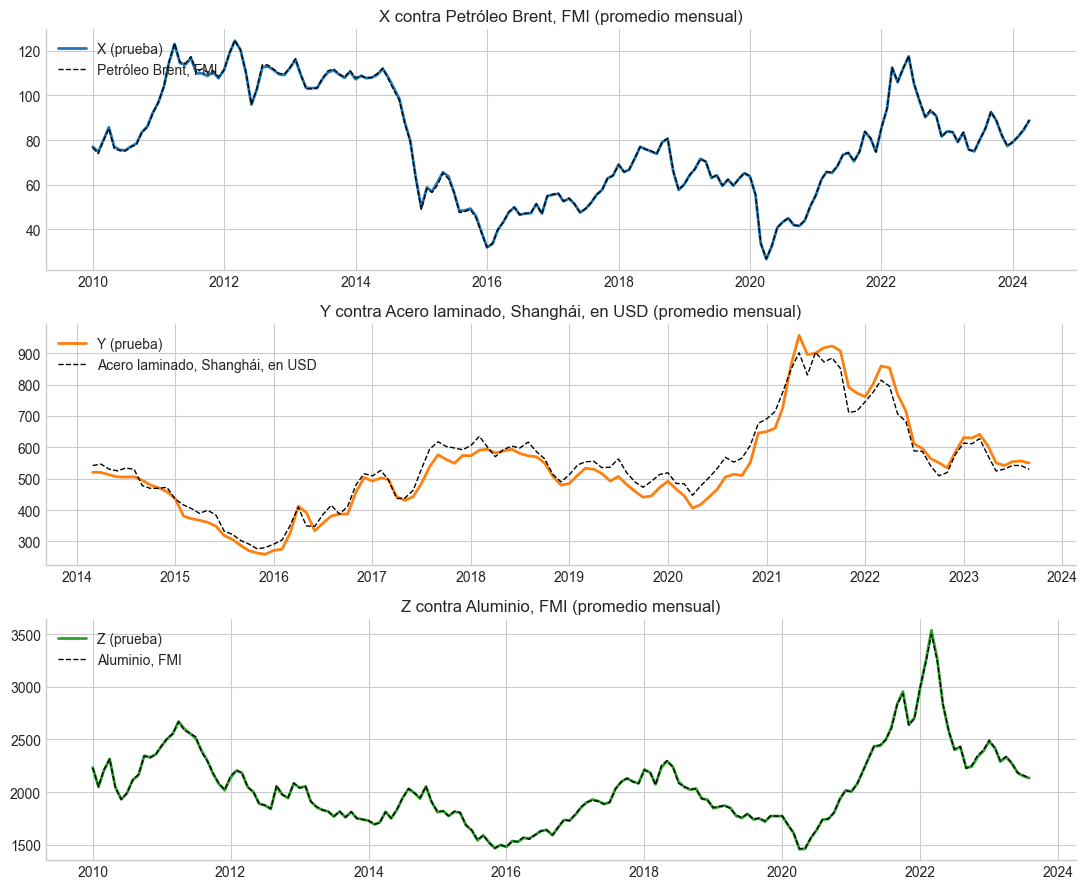

In [13]:
pares = [
    ("X", "Petróleo Brent, FMI", catalogo["POILBREUSDM"].dropna()),
    ("Y", "Acero laminado, Shanghái, en USD", aceros["Acero laminado en caliente, Shanghái (USD)"]),
    ("Z", "Aluminio, FMI", catalogo["PALUMUSDM"].dropna()),
]
fig, axes = plt.subplots(3, 1, figsize=(11, 9))
for ax, (s, nombre, ref) in zip(axes, pares):
    m = pd.concat([insumos[s].resample("MS").mean(), ref.resample("MS").mean()], axis=1, join="inner").dropna()
    m = m["2010":]
    ax.plot(m.index, m.iloc[:, 0], color=COLORES[s], linewidth=2, label=f"{s} (prueba)")
    ax.plot(m.index, m.iloc[:, 1], color="black", linewidth=1, linestyle="--", label=nombre)
    ax.set_title(f"{s} contra {nombre} (promedio mensual)")
    ax.legend(loc="upper left")
fig.tight_layout()
guardar(fig, "01_identificacion_insumos")

### Conclusión

| Serie | Materia prima | Qué tan seguro | Evidencia |
|---|---|---|---|
| **X** | Petróleo **Brent** (probablemente futuros, USD/barril) | Confirmado | Correlación de 0.995 y mismo nivel; supera a Dubái y WTI |
| **Y** | **Acero**, probablemente de China (USD/t) | Consistente | Ninguna serie del FMI coincide; mismo nivel y correlación de 0.84 con el acero de Shanghái |
| **Z** | **Aluminio** (USD/t) | Confirmado | Correlación de 0.997 y mismo nivel |

Tiene sentido para una **constructora**: el acero y el aluminio son materiales de los equipos, y el petróleo
mueve combustible, transporte y plásticos. Esta identificación **no entra al modelo**: solo sirve para que el agente
busque noticias del mercado correcto y para interpretar los resultados.

## 5. Las series en el tiempo

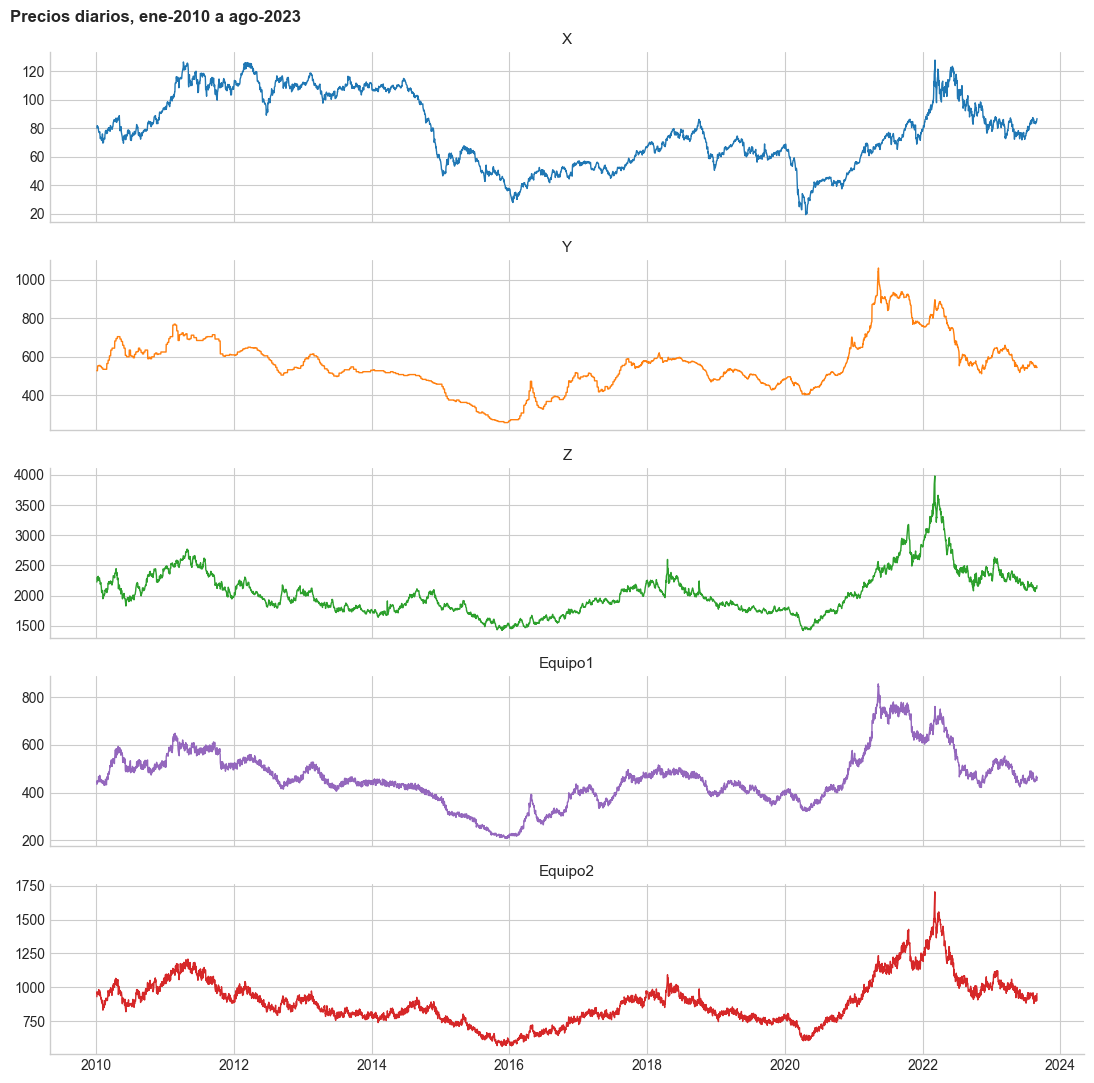

In [14]:
fig, axes = plt.subplots(5, 1, figsize=(11, 11), sharex=True)
for ax, col in zip(axes, ["X", "Y", "Z", "Equipo1", "Equipo2"]):
    ax.plot(hist.index, hist[col], color=COLORES[col], linewidth=1)
    ax.set_title(col, fontsize=11)
fig.suptitle("Precios diarios, ene-2010 a ago-2023", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "01_series_diarias")

Para compararlas en una sola gráfica se llevan a base 100 (enero 2010 = 100), con promedios mensuales:

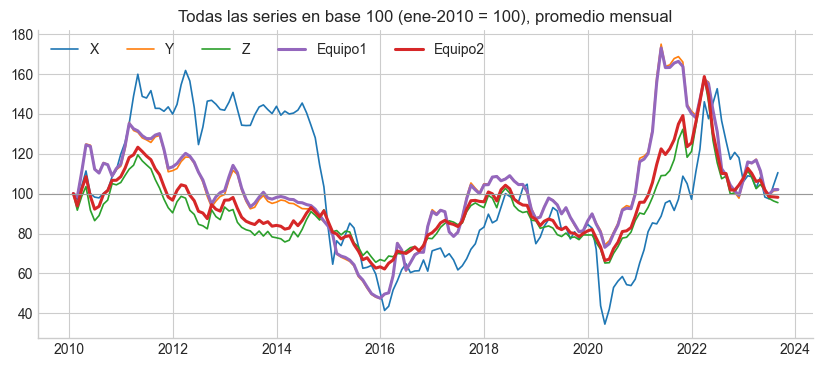

In [15]:
mensual = datos.a_mensual(hist)
base100 = 100 * mensual / mensual.iloc[0]

fig, ax = plt.subplots()
for col in base100.columns:
    ax.plot(base100.index, base100[col], color=COLORES[col], label=col,
            linewidth=2.2 if col.startswith("Equipo") else 1.2)
ax.axhline(100, color="#999", linewidth=0.8)
ax.set_title("Todas las series en base 100 (ene-2010 = 100), promedio mensual")
ax.legend(ncol=5, loc="upper left")
guardar(fig, "01_base100")

## 6. Correlaciones: niveles vs. cambios

Correlacionar **niveles** de precios con tendencia puede engañar: dos series que suben juntas se ven
correlacionadas aunque no tengan relación. Por eso se compara contra
la correlación de los **cambios mensuales**.

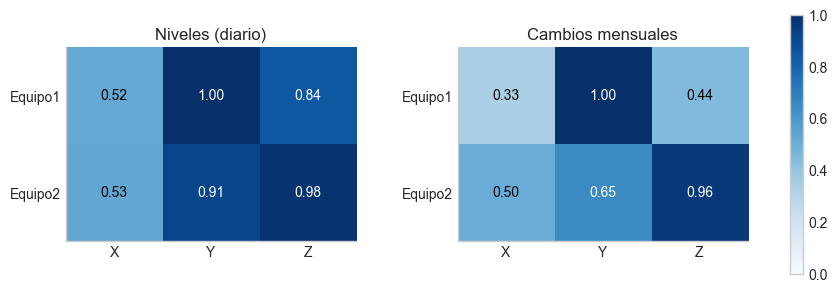

In [16]:
rend_m = np.log(mensual).diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"wspace": 0.35})
for ax, (titulo, m) in zip(axes, [("Niveles (diario)", hist.corr()), ("Cambios mensuales", rend_m.corr())]):
    sub = m.loc[["Equipo1", "Equipo2"], ["X", "Y", "Z"]]
    im = ax.imshow(sub, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(3), sub.columns)
    ax.set_yticks(range(2), sub.index)
    ax.grid(False)
    for i in range(2):
        for j in range(3):
            v = sub.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "black")
    ax.set_title(titulo)
fig.colorbar(im, ax=axes, shrink=0.8)
guardar(fig, "01_correlaciones")

- **Equipo 1** se mueve casi idéntico a "Y" (0.99 en cambios mensuales). "X" aporta algo; "Z" casi nada.
- **Equipo 2** se mueve sobre todo con "Z" (0.96), pero también con "X" y "Y".
- En niveles todo sale "correlacionado" (0.5 a 0.99): riesgo.

Esto es solo exploración; la relación formal (pesos, significancia, estabilidad) se estima en el notebook 02.

## 7. Guardar los datos limpios

In [17]:
datos.guardar_procesados(hist)
sorted(p.name for p in datos.PROCESSED.iterdir())

['backtest_modelos.csv',
 'error_por_horizonte.csv',
 'escenarios.csv',
 'historico_diario.csv',
 'historico_mensual.csv',
 'modelo_relacion.csv',
 'presupuesto_6m.csv',
 'pronostico.csv']